# Zajęcia 5 — warstwy splotowe

## Biblioteki

In [3]:
from pathlib import Path
import base64
from io import BytesIO
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({'font.size': 11, 'figure.facecolor': 'white'})
print('PyTorch', torch.__version__)

def show(fig, name):
    plt.show()


PyTorch 2.14.1+cpu


## Obraz przed filtracją

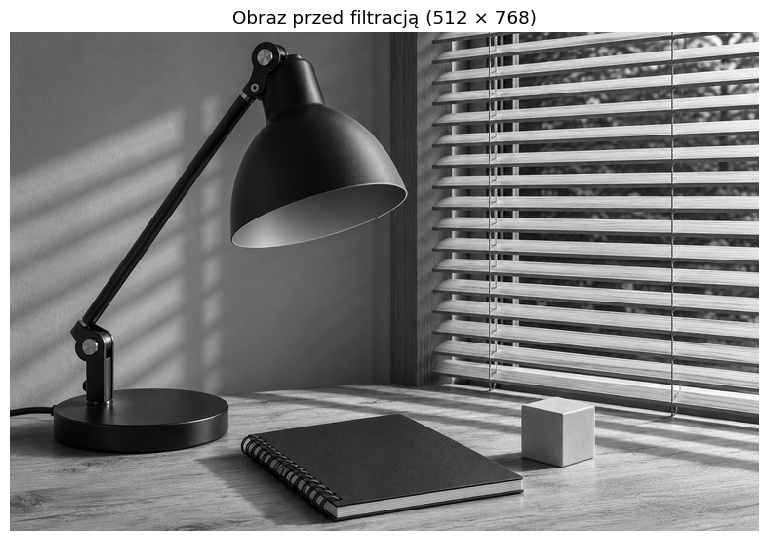

In [4]:
image_path = Path("obraz.png")
if not image_path.is_file():
    raise FileNotFoundError("Umieść obraz.png w folderze roboczym razem z notatnikiem.")

with Image.open(image_path) as image:
    pil = image.convert("L").resize((768, 512), Image.Resampling.LANCZOS)
gray = torch.from_numpy(np.array(pil)).float()[None, None] / 255
H, W = gray.shape[-2:]

def panel(items, rows, cols, size, cmap='gray'):
    fig, axes = plt.subplots(rows, cols, figsize=size, layout='constrained')
    for ax, (label, img, vmax) in zip(np.asarray(axes).flat, items):
        ax.imshow(img.squeeze(), cmap=cmap, vmin=0, vmax=vmax, interpolation='nearest')
        ax.set_title(label)
        ax.axis('off')
    return fig

fig = panel([('Obraz przed filtracją (512 × 768)', gray, 1)], 1, 1, (8, 5.3))
show(fig, 'original')

## Wymiary wyjścia

Dla każdej osi osobno: $\lfloor(N+2p-d(k-1)-1)/s\rfloor+1$.

In [5]:
def out_dim(n, k, s, p, d):
    return (n + 2*p - d*(k-1) - 1) // s + 1

configs = [(3,1,1,1), (3,2,1,1), (3,1,0,1), (3,1,1,2),
           (3,1,2,2), (5,1,2,1), (7,2,3,1)]
dim_rows = []
print('k | s | p | d | ze wzoru (H × W) | nn.Conv2d (H × W)')
with torch.inference_mode():
    for k, s, p, d in configs:
        layer = nn.Conv2d(1, 1, k, stride=s, padding=p, dilation=d)
        expected = tuple(out_dim(n, k, s, p, d) for n in (H,W))
        actual = tuple(layer(gray).shape[-2:])
        assert expected == actual
        dim_rows.append((k, s, p, d, *expected, *actual))
        print(f'{k} | {s} | {p} | {d} | {expected[0]} × {expected[1]} | {actual[0]} × {actual[1]}')

k | s | p | d | ze wzoru (H × W) | nn.Conv2d (H × W)
3 | 1 | 1 | 1 | 512 × 768 | 512 × 768
3 | 2 | 1 | 1 | 256 × 384 | 256 × 384
3 | 1 | 0 | 1 | 510 × 766 | 510 × 766
3 | 1 | 1 | 2 | 510 × 766 | 510 × 766
3 | 1 | 2 | 2 | 512 × 768 | 512 × 768
5 | 1 | 2 | 1 | 512 × 768 | 512 × 768
7 | 2 | 3 | 1 | 256 × 384 | 256 × 384


## Ręczne jądra

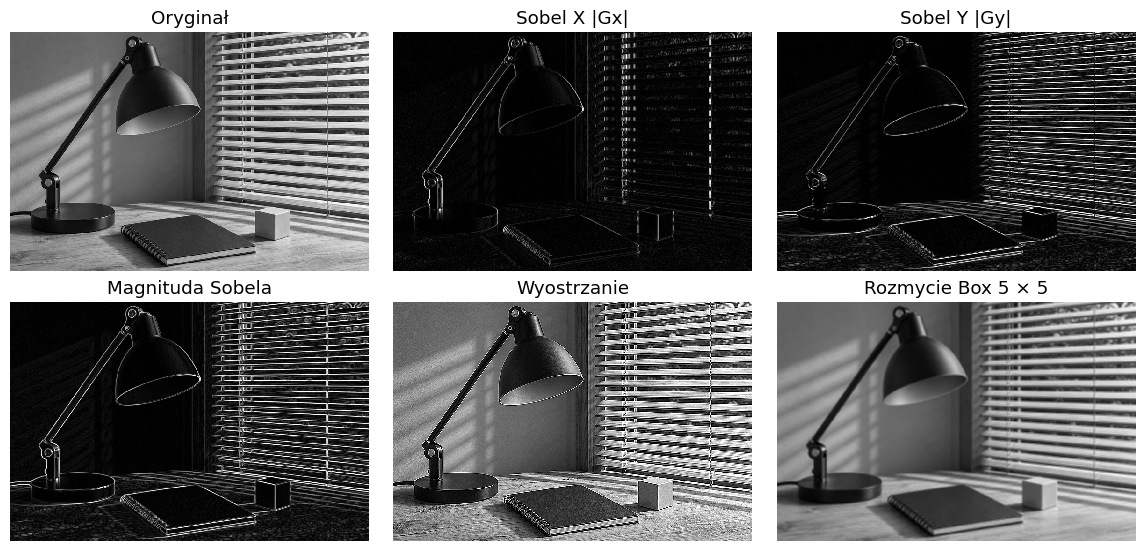

In [6]:
def kernel(entries):
    return torch.tensor(entries, dtype=torch.float32)[None,None]

sobel_x = kernel([[-1,0,1],[-2,0,2],[-1,0,1]])
sobel_y = kernel([[-1,-2,-1],[0,0,0],[1,2,1]])
sharp = kernel([[0,-1,0],[-1,5,-1],[0,-1,0]])

def filter_same(image, weights):
    p = weights.shape[-1] // 2
    return F.conv2d(F.pad(image, (p,p,p,p), mode='reflect'), weights)

gx = filter_same(gray, sobel_x)
gy = filter_same(gray, sobel_y)
magnitude = (gx.square() + gy.square()).sqrt()
sharpened = filter_same(gray, sharp)
box5 = torch.ones(1,1,5,5)/25
blurred = filter_same(gray, box5)
edge_max = float(torch.quantile(magnitude.flatten(), 0.99))
fig = panel([
    ('Oryginał',gray,1), ('Sobel X |Gx|',gx.abs(),edge_max),
    ('Sobel Y |Gy|',gy.abs(),edge_max), ('Magnituda Sobela',magnitude,edge_max),
    ('Wyostrzanie',sharpened.clamp(0,1),1), ('Rozmycie Box 5 × 5',blurred,1),
], 2, 3, (11.5, 5.4))
show(fig, 'manual')

Sobel X uwydatnia pionowe elementy żaluzji i kostki. Sobel Y silnie reaguje na poziome listwy. Magnituda łączy reakcje obu kierunków, np. na obwodzie klosza. Wyostrzanie zwiększa kontrast na granicach, a Box 5 × 5 wygładza fakturę blatu.

## Wpływ stride, padding i dilation

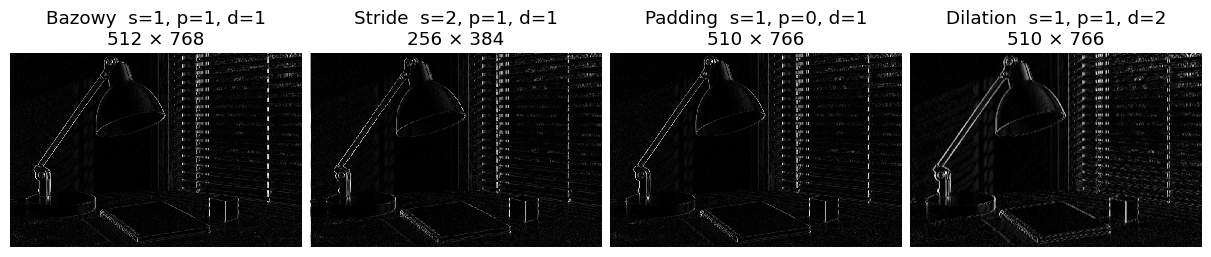

In [7]:
settings = [(1,1,1), (2,1,1), (1,0,1), (1,1,2)]
panels = []
for label, (s,p,d) in zip(['Bazowy', 'Stride', 'Padding', 'Dilation'], settings):
    y = F.conv2d(gray, sobel_x, stride=s, padding=p, dilation=d)
    h, w = y.shape[-2:]
    panels.append((f'{label}  s={s}, p={p}, d={d}\n{h} × {w}', y.abs(), edge_max))
show(panel(panels, 1, 4, (12, 3.1)), 'settings')

Stride 2 daje mapę 256 × 384 i próbuje pozycje co dwa piksele. Bez paddingu mapa 510 × 766 pomija piksele, dla których jądro wychodzi poza wejście. Dilation 2 przy p=1 również daje 510 × 766, lecz z innego powodu: próbkuje pole 5 × 5 bez dodawania wag. Widać szerszą reakcję przy kloszu.

## Porównanie rozmyć na tym samym fragmencie

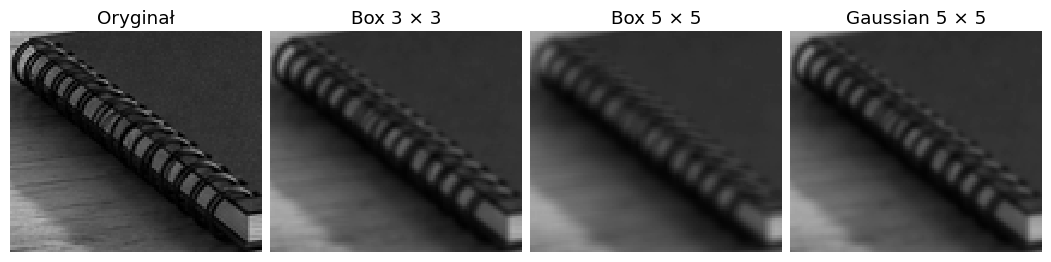

Oryginał: średni poziomy skok jasności = 0.0291
Box 3 × 3: średni poziomy skok jasności = 0.0141
Box 5 × 5: średni poziomy skok jasności = 0.0091
Gaussian 5 × 5: średni poziomy skok jasności = 0.0123


In [ ]:
box3 = torch.ones(1,1,3,3)/9
g = torch.tensor([1,4,6,4,1], dtype=torch.float32)
gaussian5 = (torch.outer(g,g)/g.sum().square())[None,None]
names = ['Oryginał', 'Box 3 × 3', 'Box 5 × 5', 'Gaussian 5 × 5']
images = [gray] + [filter_same(gray,w) for w in (box3,box5,gaussian5)]
assert all(im.shape == gray.shape for im in images)
xs, ys = slice(236, 341), slice(411, 503)
crops = [im[0,0,ys,xs] for im in images]
show(panel([(name,crop,1) for name,crop in zip(names,crops)],1,4,(10.4,2.9)), 'blur')
contrast = [float((c[:,1:] - c[:,:-1]).abs().mean()) for c in crops]
for name, value in zip(names, contrast):
    print(f'{name}: średni poziomy skok jasności = {value:.4f}')

Box 5 × 5 mocniej zlewa pierścienie spirali niż Box 3 × 3. Gaussian 5 × 5 daje wyraźniejsze granice pierścieni niż Box 5 × 5. Przy tym samym nominalnym rozmiarze Gaussian większą wagę przypisuje środkowi i jego sąsiedztwu, a Box waży wszystkie piksele jednakowo.

## Mapy cech pretrenowanego ResNet-18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\macze/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Mapy (C × H × W): (64, 112, 168) | kanały: [10, 26, 42, 19, 30, 1, 57]


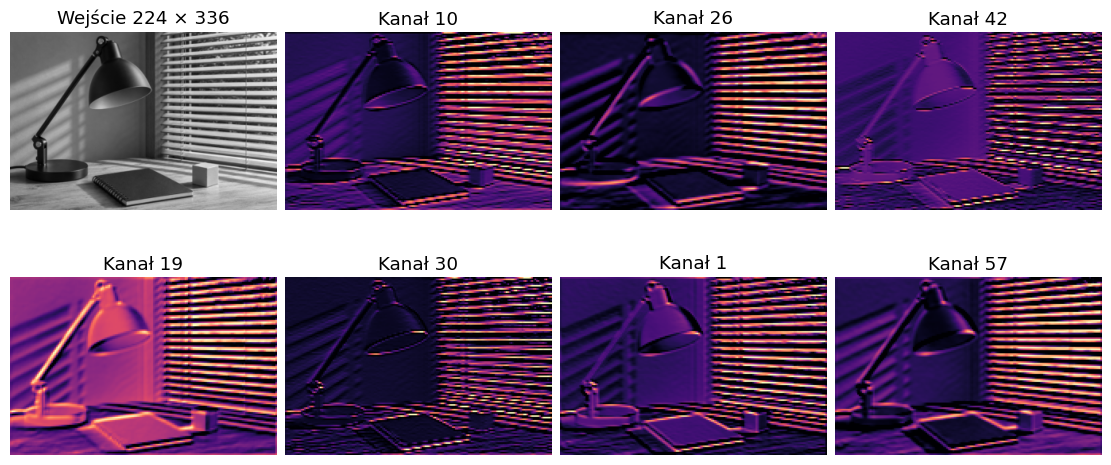

In [ ]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).eval()
small = F.interpolate(gray, size=(224,336), mode='bilinear', align_corners=False, antialias=True)
pre = weights.transforms()
inp = (small.repeat(1,3,1,1) - np.mean(pre.mean)) / np.mean(pre.std)
assert torch.equal(inp[:,0], inp[:,1]) and torch.equal(inp[:,1], inp[:,2])
with torch.inference_mode():
    activation = model.relu(model.bn1(model.conv1(inp)))[0]
ids = activation.flatten(1).std(dim=1).topk(7).indices.tolist()
print('Mapy (C × H × W):', tuple(activation.shape), '| kanały:', ids)
fig, axes = plt.subplots(2,4,figsize=(11,4.9),layout='constrained')
for i, ax in enumerate(axes.flat):
    if i == 0:
        ax.imshow(small.squeeze(), cmap='gray', vmin=0, vmax=1)
        ax.set_title('Wejście 224 × 336')
    else:
        j = ids[i-1]
        a = activation[j]
        high = max(1e-8, float(torch.quantile(a.flatten(), 0.995)))
        ax.imshow(a, cmap='magma', vmin=0, vmax=high)
        ax.set_title(f'Kanał {j}')
    ax.axis('off')
show(fig, 'features')

Kanał 10 mocno reaguje na poziome listwy żaluzji, a kanał 26 również na ukośne cienie po lewej. Kanał 19 uwydatnia ramię lampy i większe pojaśnienia. Skala kolorów jest dobierana osobno dla każdej mapy i pokazuje położenie aktywacji w obrębie kanału.